In [2]:
import numpy as np
from transformers import AutoTokenizer, AutoModel
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import os
import pymanopt
from pymanopt.manifolds import Stiefel
from pymanopt.optimizers import ConjugateGradient
import autograd.numpy as anp

# I. Data : news dataset

**I.1 dataset**

In [3]:
""" Loading data """
data = pd.read_json("data_narratives/resampled_articles_with_embeddings.json")

In [4]:
data.head(5)

,date,category,headline,short_description,link,embedding
0,2012-01-28,ENTERTAINMENT,'Girl With the Dragon Tattoo' India Release Ca...,"""Sony Pictures will not be releasing The Girl ...",https://www.huffingtonpost.com/entry/girl-with...,"[0.263354182243347, -0.467815995216369, 0.0798..."
1,2012-01-28,PARENTING,With Friends Like These,I didn't appreciate the freedom of introducing...,https://www.huffingtonpost.com/entry/mom-frien...,"[0.48301681876182506, -0.766911804676055, -0.4..."
2,2012-01-28,PARENTING,Confession: This Pediatrician Is a Sleep Softie,This may not be a great confession to make as ...,https://www.huffingtonpost.com/entry/co-sleepi...,"[0.529987752437591, -0.220514968037605, -0.154..."
3,2012-01-28,ENTERTAINMENT,"Sundance, Ice-T, and Shades of the American Ra...",Representation of the collective diaspora has ...,https://www.huffingtonpost.com/entry/sundance-...,"[-0.15862986445426902, -0.40649029612541204, -..."
4,2012-01-28,PARENTING,Teen Responsibility Doesn't Happen -- It's Nur...,Do you feel kids today are as responsible as k...,https://www.huffingtonpost.com/entry/teaching-...,"[0.576590120792388, -0.539305448532104, 0.1647..."


<Axes: xlabel='date'>

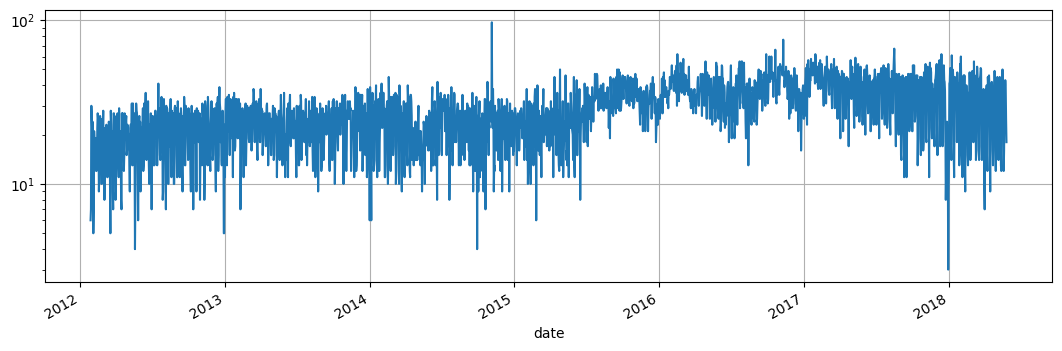

In [5]:
""" Count articles in dataset """
data.groupby('date').category.count().plot(
    figsize=(13,4), grid=True, logy=True,
)

In [6]:
data.category.value_counts()[:7]

category
POLITICS         32739
ENTERTAINMENT    16058
TRAVEL            9887
PARENTING         8677
Name: count, dtype: int64

<Axes: xlabel='date'>

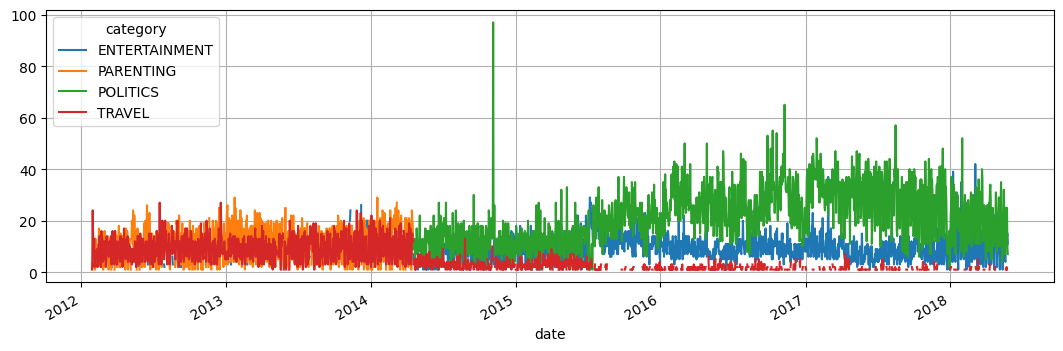

In [7]:
""" Count number of articles per category"""
daily_politics_df = data.groupby(['date', 'category']).link.count().unstack()[:'2018-06-01']
daily_politics_df.plot(
    figsize=(13,4), grid=True, logy=False,
)

In [8]:
""" load the data with embeddings """
data_with_embeddings = pd.read_json("data_narratives/resampled_articles_with_embeddings.json")
data_with_embeddings.head(5)

,date,category,headline,short_description,link,embedding
0,2012-01-28,ENTERTAINMENT,'Girl With the Dragon Tattoo' India Release Ca...,"""Sony Pictures will not be releasing The Girl ...",https://www.huffingtonpost.com/entry/girl-with...,"[0.263354182243347, -0.467815995216369, 0.0798..."
1,2012-01-28,PARENTING,With Friends Like These,I didn't appreciate the freedom of introducing...,https://www.huffingtonpost.com/entry/mom-frien...,"[0.48301681876182506, -0.766911804676055, -0.4..."
2,2012-01-28,PARENTING,Confession: This Pediatrician Is a Sleep Softie,This may not be a great confession to make as ...,https://www.huffingtonpost.com/entry/co-sleepi...,"[0.529987752437591, -0.220514968037605, -0.154..."
3,2012-01-28,ENTERTAINMENT,"Sundance, Ice-T, and Shades of the American Ra...",Representation of the collective diaspora has ...,https://www.huffingtonpost.com/entry/sundance-...,"[-0.15862986445426902, -0.40649029612541204, -..."
4,2012-01-28,PARENTING,Teen Responsibility Doesn't Happen -- It's Nur...,Do you feel kids today are as responsible as k...,https://www.huffingtonpost.com/entry/teaching-...,"[0.576590120792388, -0.539305448532104, 0.1647..."


**I.2 Resampling**

We are resampling the dataset so that, the number of articles is the same every week. We are keeping the relative weights of all categories

In [9]:
import pandas as pd
import numpy as np

def resample_constant_weekly(df, target_per_week=None, random_state=42):
    """
    Resample un DataFrame pour avoir un nombre constant d'articles par semaine,
    tout en conservant les proportions relatives des catégories.

    Parameters
    ----------
    df : pd.DataFrame
        Doit contenir les colonnes 'date' et 'category'.
    target_per_week : int ou None
        Nombre cible d'articles par semaine. Si None, utilise la médiane.
    random_state : int
        Graine aléatoire pour la reproductibilité.

    Returns
    -------
    pd.DataFrame : DataFrame rééchantillonné.
    """
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])

    # ── 1. Créer un identifiant de semaine ──────────────────────────
    iso = df['date'].dt.isocalendar()
    df['year_week'] = iso['year'].astype(str) + '-W' + \
                      iso['week'].astype(str).str.zfill(2)

    # ── 2. Déterminer le nombre cible par semaine ───────────────────
    weekly_counts = df.groupby('year_week').size()
    if target_per_week is None:
        target_per_week = int(weekly_counts.median())

    print(f"{'Nombre cible par semaine':<35}: {target_per_week}")
    print(f"{'Nb original — min / médiane / max':<35}: "
          f"{weekly_counts.min()} / {weekly_counts.median():.0f} / {weekly_counts.max()}")

    # ── 3. Rééchantillonnage semaine par semaine ────────────────────
    rng = np.random.RandomState(random_state)
    resampled_frames = []

    for week, week_df in df.groupby('year_week'):

        # 3a. Proportions des catégories cette semaine
        cat_counts      = week_df['category'].value_counts()
        cat_proportions = cat_counts / cat_counts.sum()

        # 3b. Allocation proportionnelle du budget "target_per_week"
        raw_alloc = cat_proportions * target_per_week
        alloc     = np.floor(raw_alloc).astype(int)

        # 3c. Distribuer le reste aux catégories ayant la plus grande
        #     partie fractionnaire (méthode des plus forts restes)
        remainder        = target_per_week - alloc.sum()
        fractional_parts = raw_alloc - alloc
        top_cats         = fractional_parts.nlargest(int(remainder)).index
        alloc[top_cats] += 1

        # 3d. Échantillonner dans chaque catégorie
        for cat, n_sample in alloc.items():
            if n_sample == 0:
                continue
            cat_df  = week_df[week_df['category'] == cat]
            replace = n_sample > len(cat_df)          # avec remise si nécessaire
            sampled = cat_df.sample(n=n_sample, replace=replace,
                                    random_state=rng)
            resampled_frames.append(sampled)

    # ── 4. Concaténation et nettoyage ───────────────────────────────
    result = pd.concat(resampled_frames, ignore_index=True)
    result.drop(columns=['year_week'], inplace=True)

    return result

In [10]:
resampled_data = resample_constant_weekly(data)
resampled_data.head(5)

Nombre cible par semaine           : 185
Nb original — min / médiane / max  : 13 / 185 / 361


,date,category,headline,short_description,link,embedding
0,2012-01-29,ENTERTAINMENT,World Preview Of Madonna's 'Give Me All Your L...,Fox and American Idol snagged the exclusive wo...,https://www.huffingtonpost.comhttp://insidetv....,"[0.46883603930473305, -0.654365897178649, -0.4..."
1,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",Bow Wow needs to hire himself a new accountant...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.518027663230896, 0.041439708322286, -0.5698..."
2,2012-01-29,ENTERTAINMENT,'Terminator 3' Star Nick Stahl Arrested For No...,Nick Stahl found himself a little short on cas...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.506560206413269, -0.08877640962600701, -0.5..."
3,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",Bow Wow needs to hire himself a new accountant...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.518027663230896, 0.041439708322286, -0.5698..."
4,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",Bow Wow needs to hire himself a new accountant...,https://www.huffingtonpost.comhttp://www.tmz.c...,"[0.518027663230896, 0.041439708322286, -0.5698..."


<Axes: xlabel='date'>

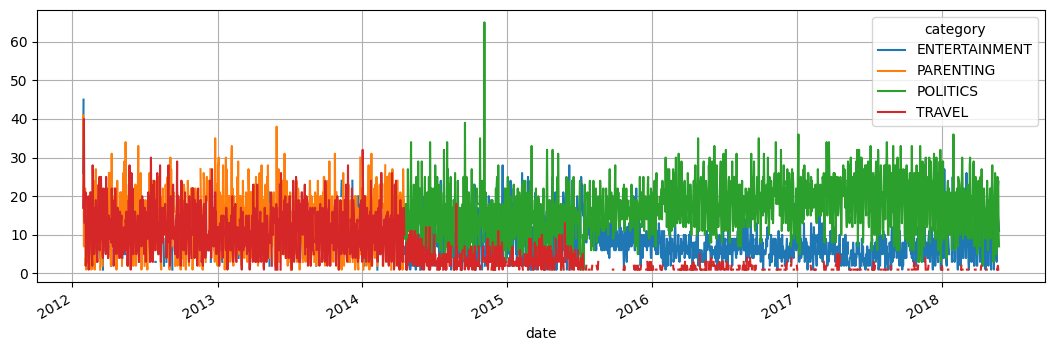

In [11]:
""" Count number of articles per category"""
daily_politics_df = resampled_data.groupby(['date', 'category']).link.count().unstack()[:'2018-06-01']
daily_politics_df.plot(
    figsize=(13,4), grid=True, logy=False,
)

<Axes: xlabel='date'>

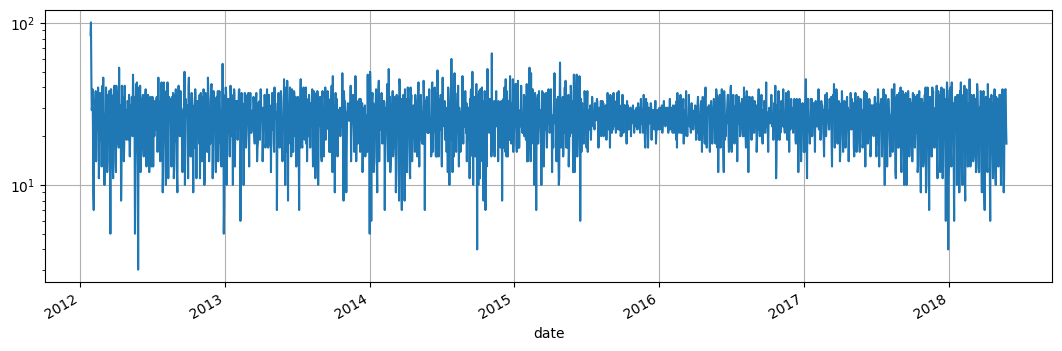

In [12]:
""" Count articles in dataset """
resampled_data.groupby('date').category.count().plot(
    figsize=(13,4), grid=True, logy=True,
)

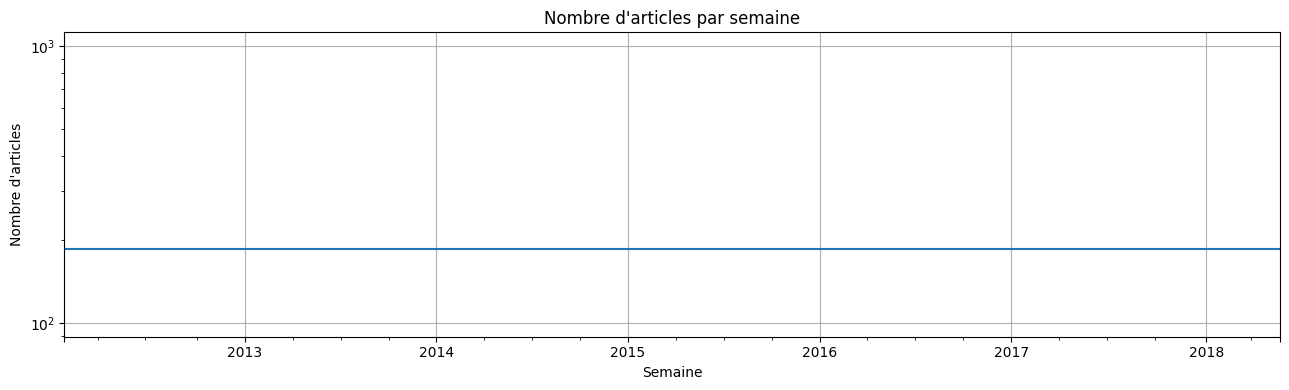

In [13]:
# S'assurer que 'date' est en datetime
resampled_data['date'] = pd.to_datetime(resampled_data['date'])

# ── Option 1 : Avec resample (recommandé) ──────────────────────────
resampled_data.set_index('date') \
    .resample('W')['category'] \
    .count() \
    .plot(figsize=(13, 4), grid=True, logy=True,
          title="Nombre d'articles par semaine")

plt.ylabel("Nombre d'articles")
plt.xlabel("Semaine")
plt.tight_layout()
plt.show()

## II. Narratives and orthogonalization ##


**I.1 Narratives**

We chose 3 narratives per chapter corresponding to the categories of the news in the dataset + two categories
See the conversation with chatGPT: https://chatgpt.com/share/698f503c-99d0-800d-9422-4643bc0a4340

In [14]:
narratives_by_chapter = {
    "politics": {
        "trump": "Donald Trump will be elected because widespread economic discontent, distrust of political elites, and cultural backlash against globalization and immigration fuel support for an outsider candidate who promises disruption, national restoration, and direct confrontation with established institutions and media.",
        "obama": "Barack Obama will be re-elected because a slowly recovering economy, the successful framing of policy achievements such as healthcare reform, and strong coalition support among minorities, younger voters, and urban populations outweigh voter dissatisfaction and sustain confidence in incremental progress.",
        "obamacare": "The Affordable Care Act, often called Obamacare, is needed because it expands access to health insurance for millions of people who were previously uninsured or underinsured. The law aims to reduce healthcare costs over time, protect individuals with preexisting conditions, and strengthen the healthcare system by spreading risk more broadly across the population.",
    },
    "society": {
        "black_lives": "Black Lives Matter emerged as a movement responding to systemic racism, police violence, and unequal treatment of Black Americans within the criminal justice system. It connected individual incidents of violence to broader structural inequalities, using protests, social media, and cultural discourse to demand accountability, reform, and recognition of racial injustice in American society.",
        "shooting": "Mass shootings in the United States persist because of the widespread availability of firearms, gaps in mental health support, social isolation, media amplification of violence, and political gridlock that prevents comprehensive gun policy reform despite recurring public outrage.",
        "data_privacy": "Data privacy is important because personal information is increasingly collected, stored, and analyzed by governments and private companies, often without clear consent or transparency. Protecting data privacy helps preserve individual autonomy, prevents misuse and surveillance, and maintains trust in digital technologies that shape modern economic, social, and political life.",
        "paris_agreement": "The Paris Agreement is important because it represents a global commitment to limit climate change by reducing greenhouse gas emissions and promoting international cooperation. By setting shared goals and encouraging accountability, the agreement aims to mitigate the environmental, economic, and social risks associated with rising global temperatures and extreme weather events.",
        "school_shooting": "There are many ways to prevent school shootings because the issue involves multiple social, psychological, and policy factors. Approaches such as improving mental health support, enhancing school safety measures, fostering community engagement, and addressing access to firearms can collectively reduce the risk of violence.",
    },
    "geopolitics": {
        "ISIS": "ISIS attacks are happening because of prolonged instability in parts of the Middle East, power vacuums created by war, and sectarian divisions that extremist groups exploit. The organization uses violence and terrorism to assert control, spread fear, and gain international attention, while drawing recruits through ideological propaganda and grievances linked to political and economic marginalization.",
        "russia_crimea": "Russia is annexing Crimea because of strategic and political interests tied to regional influence, military access to the Black Sea, and concerns about Ukraine's alignment with Western institutions. The move follows political instability in Ukraine and is justified by Russian authorities as protecting ethnic Russians and national security, while being widely viewed internationally as a violation of Ukrainian sovereignty.",
        "brexit": "The United Kingdom votes to leave the European Union because of long-standing concerns about national sovereignty, immigration, and the perceived loss of democratic control to EU institutions. Economic uncertainty, regional inequality, and dissatisfaction with political elites also contribute to a referendum outcome driven by competing visions of globalization and national identity.",
    },
    "entertainment": {
        "game_of_thrones": "Game of Thrones is innovative because it combines cinematic production values with long-form television storytelling, complex characters, and morally ambiguous narratives. By subverting traditional fantasy tropes and embracing unpredictability, the series reshaped audience expectations and helped elevate television as a medium for ambitious, high-budget storytelling.",
        "me_too": "The Me Too movement is a revolution because it fundamentally changes how sexual harassment and abuse are discussed, exposing systemic power imbalances across industries. By amplifying personal testimony and collective accountability, the movement challenges long-standing norms of silence and reshapes cultural and institutional responses to misconduct.",
        "stream_music": "Streaming-first music releases are changing the industry because they shift power away from traditional distribution models toward digital platforms and data-driven consumption. This approach alters how artists release, promote, and monetize music, emphasizing continuous engagement, algorithmic visibility, and global accessibility over physical sales and scheduled releases.",
    },
    "travel": {
        "MH370": "The disappearance of Malaysia Airlines Flight MH370 is terrible because it represents a profound human tragedy marked by uncertainty, loss, and unanswered questions. The incident exposed vulnerabilities in global aviation tracking and left families and the international community without clear explanations or closure.",
        "airlines": "Airlines push premium economy seating and loyalty-program changes because they seek to increase revenue in a highly competitive industry facing rising costs and thin margins. By segmenting passengers and monetizing comfort and perks, airlines aim to maximize profits while adapting to changing traveler expectations and spending behavior.",
        "rentals": "Cities begin regulating short-term rentals because rapid growth of platforms like Airbnb affects housing availability, neighborhood stability, and local infrastructure. Policymakers respond to concerns about rising rents, tourism pressure, and fairness between traditional hotels and peer-to-peer accommodations.",
        "ebola": "Ebola is dangerous because it is a highly contagious and often fatal disease that can spread rapidly in areas with limited healthcare infrastructure. Outbreaks generate fear, disrupt travel and economies, and highlight global vulnerabilities in disease detection, containment, and public health preparedness.",
    },
    "parenting": {
        "same_sex": "Same-sex marriage is a revolution because it fundamentally reshapes legal definitions of family, equality, and civil rights. By extending marriage protections to LGBTQ+ couples, it challenges long-standing social norms and affirms the principle that legal recognition should not depend on sexual orientation.",
        "parental_leave": "Paid parental leave is a change because it redefines the relationship between work, family, and economic security. By allowing parents time to care for newborns without losing income or employment, it shifts expectations about caregiving responsibilities and workplace support for families.",
        "screen_time": "Screen time for teens is dangerous because excessive use of digital devices can affect mental health, sleep patterns, and social development. Constant exposure to social media and online comparison may increase anxiety, reduce attention, and shape behavior during a critical stage of emotional growth.",
    },
}

**II.2 Orthogonalization**

Our goal is to find a representative $V_i$ of each normalized narrative's embedding $N_i$. We are adding the mean of (N_i)_i as a last "narrative". Thus, we solve the following optimization under constraints problem: 

$$ \text{argmax}_{(V_1, ..., V_n)} \text{min}_{i} N_i^TV_i$$
$$s.t, ||V_i|| \le 1, N_i^TV_i \ge 0, V_i^TV_j = 0$$

In [15]:
def gram_schmidt(N_matrix):
    """Orthogonalisation de Gram-Schmidt."""
    n, dim = N_matrix.shape
    V = np.zeros_like(N_matrix, dtype=float)

    for i in range(n):
        v = N_matrix[i].copy().astype(float)
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        norm = np.linalg.norm(v)
        V[i] = v / norm if norm > 1e-10 else v

    return V

In [16]:
def stiefel_optimize(N_matrix, softmin_temp=0.05, max_iter=300):
    """
    Optimisation sur la variété de Stiefel.
    Maximise min_i <N_i, V_i> avec V @ V.T = I.
    """
    n, dim = N_matrix.shape

    # Variété de Stiefel
    manifold = Stiefel(dim, n)

    @pymanopt.function.autograd(manifold)
    def cost(V):
        Vt = V.T
        projections = anp.sum(N_matrix * Vt, axis=1)
        softmin = -softmin_temp * anp.log(anp.sum(anp.exp(-projections / softmin_temp)))
        return -softmin

    problem = pymanopt.Problem(manifold, cost)
    optimizer = ConjugateGradient(verbosity=1, max_iterations=max_iter)

    # Initialisation avec Gram-Schmidt
    V_init = gram_schmidt(N_matrix).T
    result = optimizer.run(problem, initial_point=V_init)

    return result.point.T, result

# III. Compute the narratives and orthogonal representatives 

The narratives need to be normalized before the orthogonalization, bacause we are optimizing on the dot product thus, if the norm of one $N_i$ is arbitrarly bigger than the others, this is inducing a bias. We don't want such a bias because after, we will work with cosine similarities. 

However, to compute the residuals, we need to keep the narratives without normalization. We denote the non-normalized narratives by $N_i^*$. Thus, the $R_i = N_i^* - V_i$

In [17]:
""" To compute embeddings with ModernBERT """

def load_model(model_name="answerdotai/ModernBERT-base"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval()
    return tokenizer, model

def get_embedding(text, tokenizer, model, device):
    """
    Generate embedding for a given text using ModernBERT.
    Uses mean pooling of the last hidden state.
    """
    # Tokenize and prepare input
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                      max_length=512, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get embeddings
    with torch.no_grad():
        outputs = model(**inputs)
        # Mean pooling
        embeddings = outputs.last_hidden_state.mean(dim=1)

    return embeddings.cpu().numpy().flatten()

In [18]:
chapter_names = narratives_by_chapter.keys()

In [19]:
""" Compute narratives embeddings and solve orthogonality problem """
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained("answerdotai/ModernBERT-base")
model = AutoModel.from_pretrained("answerdotai/ModernBERT-base").to(device)
model.eval()

rows = []
for chapter, narratives in narratives_by_chapter.items():
    for title, text in narratives.items():
        rows.append({"chapter": chapter, "title": title, "text": text})

narrative_matrix_unorm = np.array([get_embedding(row["text"], tokenizer, model, device) for row in rows])
narrative_matrix = np.array([narrative_matrix_unorm[i] / np.linalg.norm(narrative_matrix_unorm[i]) for i in range(len(narrative_matrix_unorm))])


""" normalize each narrative"""
print(narrative_matrix.shape)

orthogonal_matrix, score = stiefel_optimize(narrative_matrix)

residuals_matrix = narrative_matrix_unorm - orthogonal_matrix
""" normalize the residuals matrix """
residuals_matrix = np.array([residuals_matrix[i] / np.linalg.norm(residuals_matrix[i]) for i in range(len(residuals_matrix))])

/users/eleves-b/2023/juliette.anglade/Desktop/Code/myenv/lib64/python3.9/site-packages/networkx/utils/backends.py:135: RuntimeWarning: networkx backend defined more than once: nx-loopback
  backends.update(_get_backends("networkx.backends"))
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disablin

(21, 768)
Optimizing...
Terminated - min grad norm reached after 51 iterations, 0.10 seconds.



In [20]:
narratives = pd.DataFrame([{**rows[i], "embedding": narrative_matrix[i]} for i in range(len(rows))])
narratives_orth = pd.DataFrame([{"chapter": rows[i]["chapter"], "title": f"{rows[i]['title']}_orth", "text": rows[i]["text"], "embedding": orthogonal_matrix[i]} for i in range(len(rows))])
narratives_complementary = pd.DataFrame([{"chapter": rows[i]["chapter"], "title": f"{rows[i]['title']}_comple", "text": rows[i]["text"], "embedding": residuals_matrix[i]} for i in range(len(rows))])

narratives.to_csv("./data_narratives/narratives.csv", index=False)
narratives_orth.to_csv("./data_narratives/narratives_orth.csv", index=False)
narratives_complementary.to_csv("./data_narratives/narratives_complementary.csv", index=False)

In [21]:
narrative_names = (narratives.chapter + ':' + narratives.title).to_list()

orthogonal_names = (narratives_orth.chapter + ':' + narratives_orth.title).to_list()

residuals_names = (narratives_complementary.chapter + ':' + narratives_complementary.title).to_list()


**III.2 Visualization**

In [22]:
cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, orthogonal_matrix, residuals_matrix]))

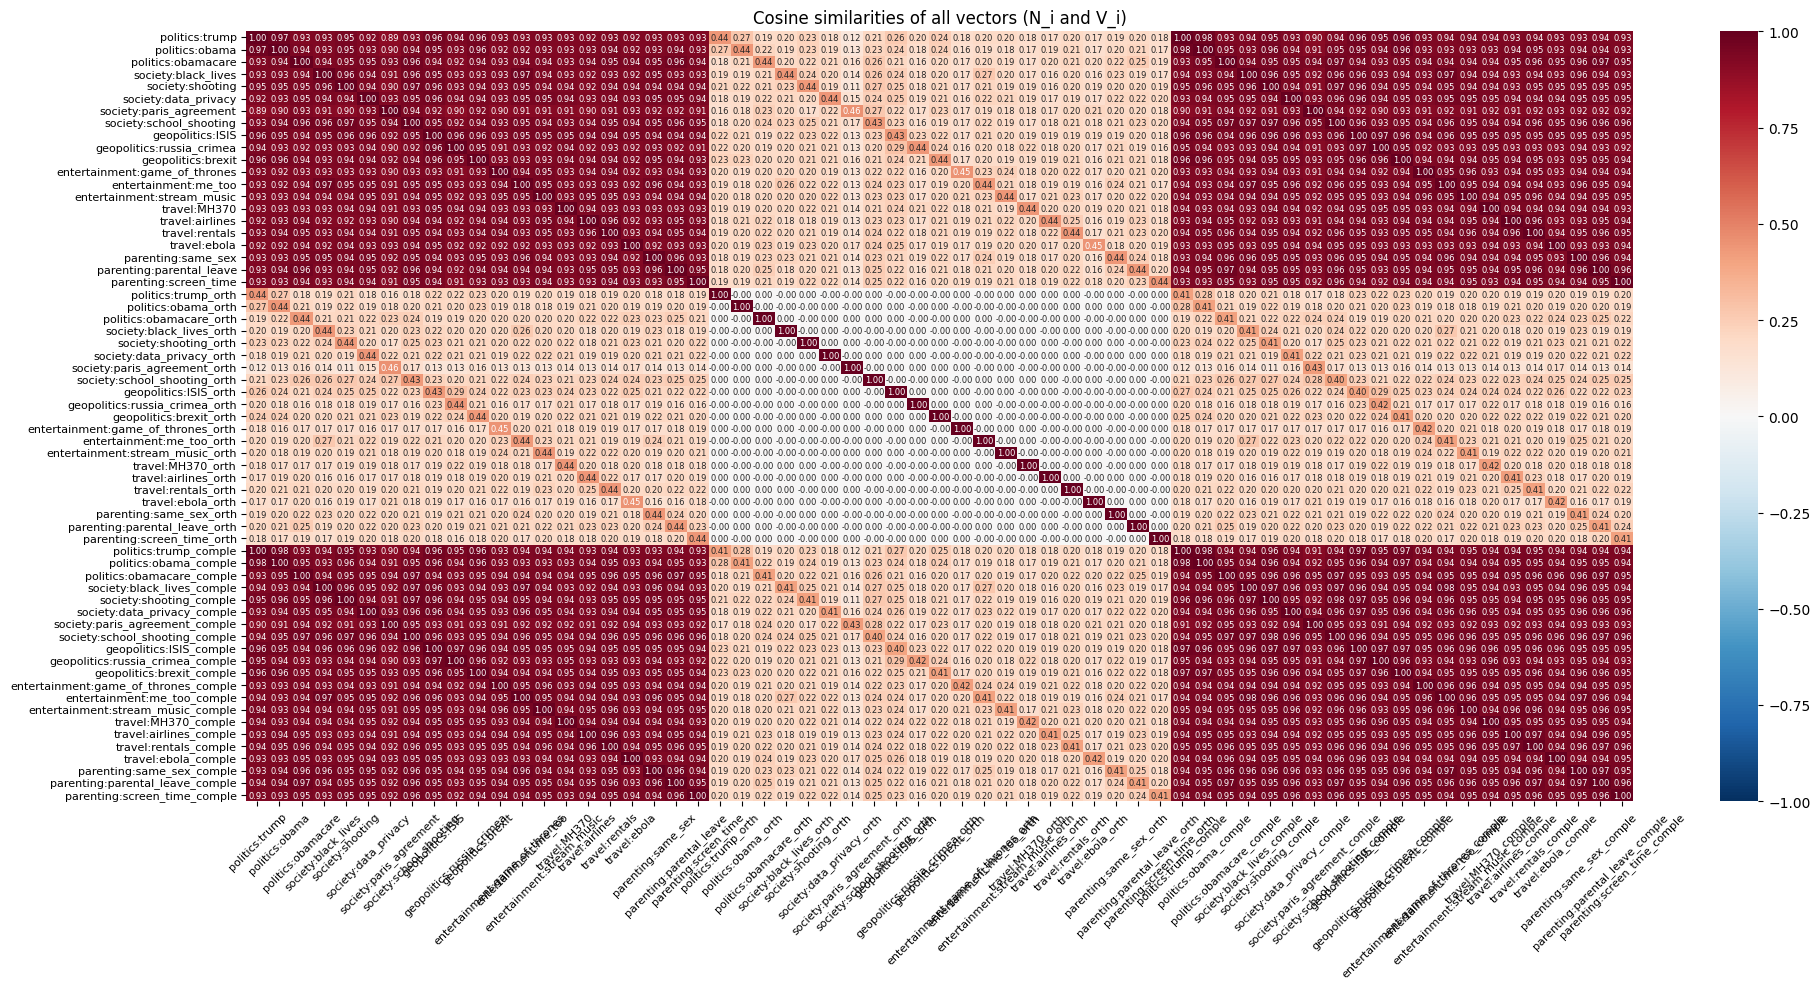

In [23]:
fig, axes = plt.subplots(1, 1, figsize=(20, 10))
# Heatmap for all vectors N_i and V_i, N_i - V_i
sns.heatmap(
    cosine_sim_all,
    xticklabels=narrative_names + orthogonal_names + residuals_names,
    yticklabels=narrative_names + orthogonal_names + residuals_names,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors (N_i and V_i)', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.savefig('cosine_similarities_all.png', dpi=150, bbox_inches='tight')
plt.show()

**III.3 Orthogonalization adding the mean of the narratives**

Now, let's see what happens if we had the mean of the narratives, i.e : $M = \frac1n \sum_i N_i$

In [24]:
narratives_with_mean_matrix = np.vstack([narrative_matrix, narrative_matrix.mean(axis=0)])
narratives_with_mean_matrix_unorm = np.vstack([narrative_matrix_unorm, narrative_matrix_unorm.mean(axis=0)])
orthogonal_with_mean_matrix, _= stiefel_optimize(narratives_with_mean_matrix)
rediduals_with_mean_matrix = narratives_with_mean_matrix_unorm - orthogonal_with_mean_matrix

Optimizing...
Terminated - min grad norm reached after 87 iterations, 0.24 seconds.



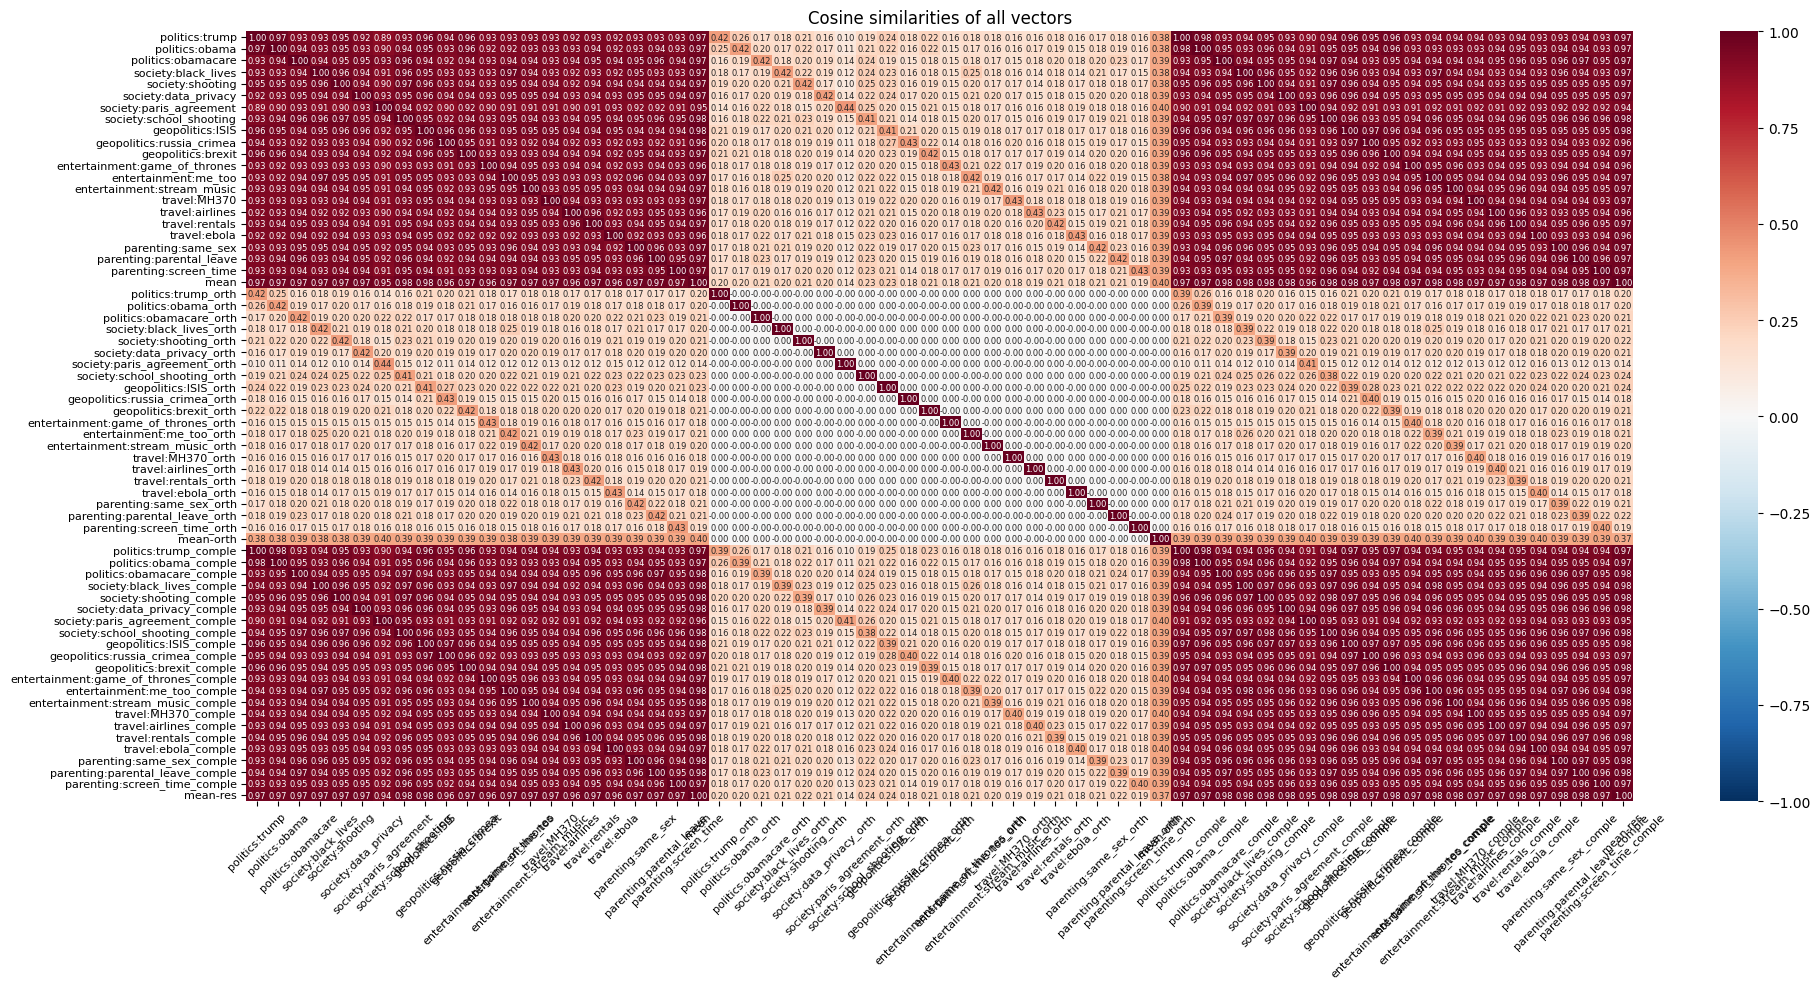

In [25]:
"""visualization"""
 
cosine_sim_all_with_mean = cosine_similarity(np.vstack([narratives_with_mean_matrix, orthogonal_with_mean_matrix, rediduals_with_mean_matrix]))

fig, axes = plt.subplots(1, 1, figsize=(20, 10))
# Heatmap for all vectors N_i and V_i, N_i - V_i
sns.heatmap(
    cosine_sim_all_with_mean,
    xticklabels=narrative_names+ ["mean"] + orthogonal_names + ["mean-orth"] + residuals_names + ["mean-res"],
    yticklabels=narrative_names + ["mean"] + orthogonal_names + ["mean-orth"] + residuals_names + ["mean-res"],
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 6}
)
axes.set_title('Cosine similarities of all vectors', fontsize=12)
axes.tick_params(axis='x', rotation=45, labelsize=8)
axes.tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.show()

Je ne vois pas exactement ce qu'apporte la moyenne dans ce cas. Nous accédons à un $V_mean$, représentant de la moyenne: est-ce que c'est vraiment intéressant pour la suite du travail ?
Sinon, on pourrait fixer la moyenne ? 

# IV Main computations: cosine similarities with $N_i$, $V_i$, $R_i$

For this part, we are keeping the $V_i$ and $R_i$ without adding the mean in the orthogonalization process.

In [26]:
"""Create dataframe with the cosine similarity with orthogonal narratives"""
from tqdm.notebook import tqdm
from sklearn.metrics.pairwise import cosine_similarity

print("Computing cosine similarities with narratives and orthogonal narratives...")


time_series_data = []
gdir = './data_narratives'

for idx, row in tqdm(resampled_data.iterrows(), total=len(resampled_data)):
    # Get article embedding
    article_embedding = row['embedding']
    if isinstance(article_embedding, list):
        article_embedding = np.array(article_embedding)
    
    info_similarities = {
        'date': row['date'],
        'category': row['category'],
        'headline': row['headline'],
        'link': row.get('link', '')
    }
    
    # Compute cosine similarities with narratives (vectorized)
    similarities_narratives = cosine_similarity(
        article_embedding.reshape(1, -1),
        narrative_matrix
    )[0]
    
    for name, sim in zip(narrative_names, similarities_narratives):
        info_similarities[f"{name}"] = float(sim)
    
    # Compute cosine similarities with orthogonal narratives (vectorized)
    similarities_orthogonal = cosine_similarity(
        article_embedding.reshape(1, -1),
        orthogonal_matrix
    )[0]

    for name, sim in zip(orthogonal_names, similarities_orthogonal):
        info_similarities[f"{name}"] = float(sim)

    # Compute cosine similarities with residuals narratives (vectorized)
    similarities_residuals = cosine_similarity(
        article_embedding.reshape(1, -1),
        residuals_matrix
    )[0]
    
    for name, sim in zip(residuals_names, similarities_residuals):
        info_similarities[f"{name}"] = float(sim)

    time_series_data.append(info_similarities)

# Save to CSV
ts_df = pd.DataFrame(time_series_data)
filepath = os.path.join(gdir, 'narrative_exposures_with_orthogonal.csv')
os.makedirs(gdir, exist_ok=True)
ts_df.to_csv(filepath, index=False)
print(f"✓ Saved to: {filepath}")
print(f"Shape: {ts_df.shape}")
print(f"Columns: {ts_df.columns.tolist()[:10]}...")  # Show first 10 columns

Computing cosine similarities with narratives and orthogonal narratives...


  0%|          | 0/61235 [00:00<?, ?it/s]

✓ Saved to: ./data_narratives/narrative_exposures_with_orthogonal.csv
Shape: (61235, 67)
Columns: ['date', 'category', 'headline', 'link', 'politics:trump', 'politics:obama', 'politics:obamacare', 'society:black_lives', 'society:shooting', 'society:data_privacy']...


In [27]:
ts_df.head()

,date,category,headline,link,politics:trump,politics:obama,politics:obamacare,society:black_lives,society:shooting,society:data_privacy,...,entertainment:game_of_thrones_comple,entertainment:me_too_comple,entertainment:stream_music_comple,travel:MH370_comple,travel:airlines_comple,travel:rentals_comple,travel:ebola_comple,parenting:same_sex_comple,parenting:parental_leave_comple,parenting:screen_time_comple
0,2012-01-29,ENTERTAINMENT,World Preview Of Madonna's 'Give Me All Your L...,https://www.huffingtonpost.comhttp://insidetv....,0.879134,0.869649,0.896252,0.877156,0.873109,0.872954,...,0.911943,0.893052,0.911328,0.895476,0.893766,0.905387,0.888232,0.903037,0.905670,0.894828
1,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",https://www.huffingtonpost.comhttp://www.tmz.c...,0.899576,0.898255,0.917172,0.899961,0.889841,0.902018,...,0.914703,0.907177,0.914464,0.916687,0.917317,0.928718,0.898105,0.919245,0.926947,0.913679
2,2012-01-29,ENTERTAINMENT,'Terminator 3' Star Nick Stahl Arrested For No...,https://www.huffingtonpost.comhttp://www.tmz.c...,0.893941,0.894524,0.898520,0.881942,0.886644,0.886112,...,0.915085,0.900163,0.906981,0.911885,0.914196,0.915333,0.886116,0.907040,0.915627,0.900193
3,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",https://www.huffingtonpost.comhttp://www.tmz.c...,0.899576,0.898255,0.917172,0.899961,0.889841,0.902018,...,0.914703,0.907177,0.914464,0.916687,0.917317,0.928718,0.898105,0.919245,0.926947,0.913679
4,2012-01-29,ENTERTAINMENT,"Bow Wow Has Tax Liens From 2006, 2008, And 2010",https://www.huffingtonpost.comhttp://www.tmz.c...,0.899576,0.898255,0.917172,0.899961,0.889841,0.902018,...,0.914703,0.907177,0.914464,0.916687,0.917317,0.928718,0.898105,0.919245,0.926947,0.913679


# V Visualization

**V.1 All new, all narratives**

1) Narratives $N_i$

In [28]:
""" Prepare data for visualization """
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col and '_comple' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]
residuals_cols = [col for col in all_cols if '_comple' in col]

# Get unique news categories
news_categories = sorted(ts_df['category'].unique()) 


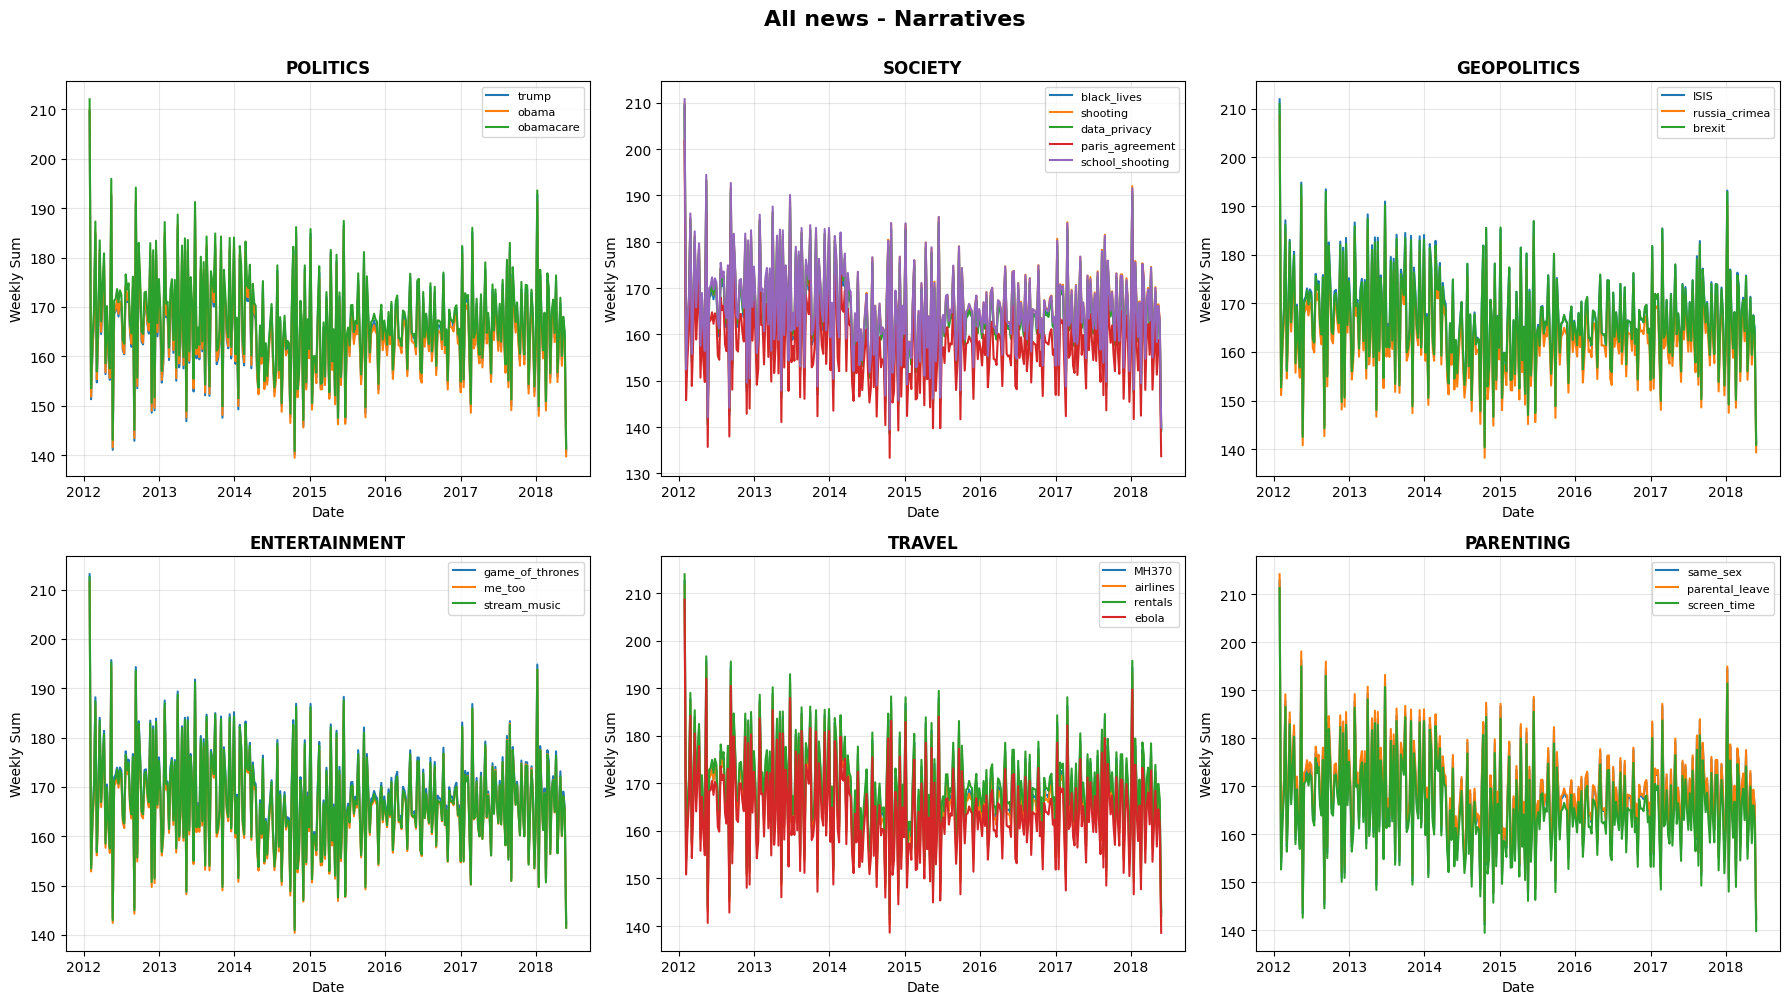

In [29]:
""" Visualization of cosine time series for pure narratives """


# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_narrative_cols = [col for col in narrative_cols if col.startswith(chapter + ':')]
        
    if not chapter_narrative_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_narrative_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Narratives', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


2) Orthogonal representatives $V_i$

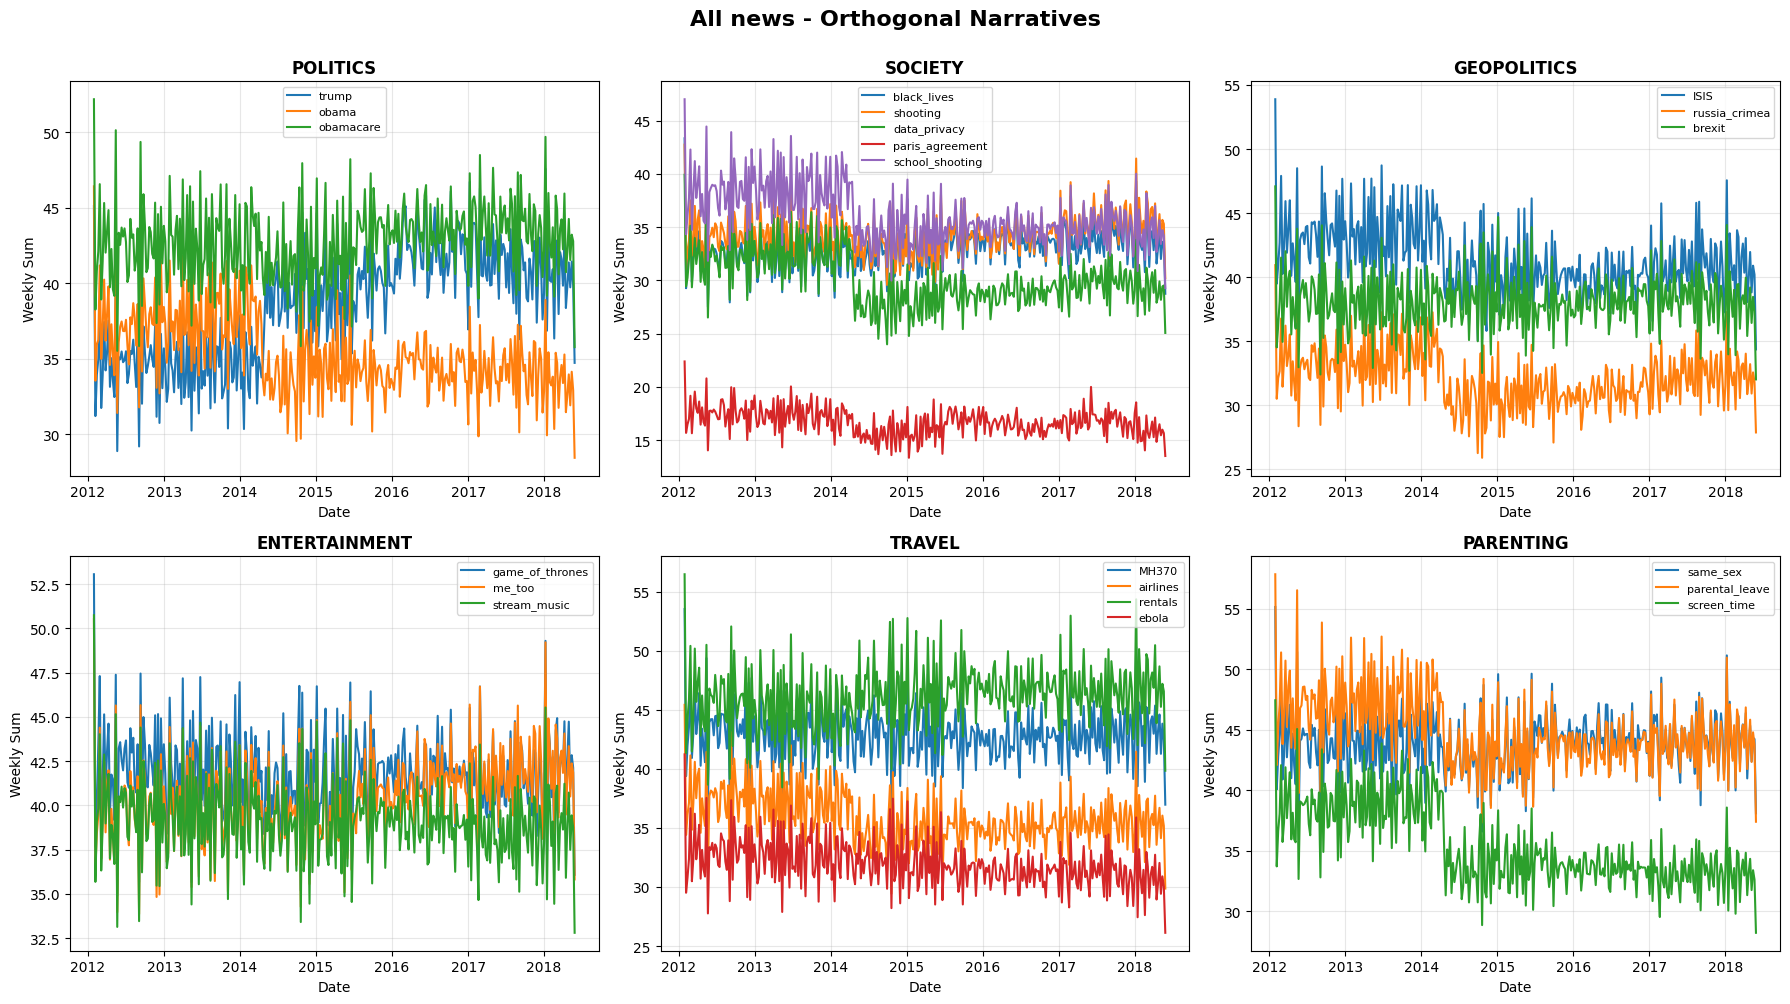

In [30]:
""" Visualization of cosine time series for pure narratives """


# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_orth_cols = [col for col in orthogonal_cols if col.startswith(chapter + ':')]
        
    if not chapter_orth_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_orth_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Orthogonal Narratives', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


3) Residuals $R_i$

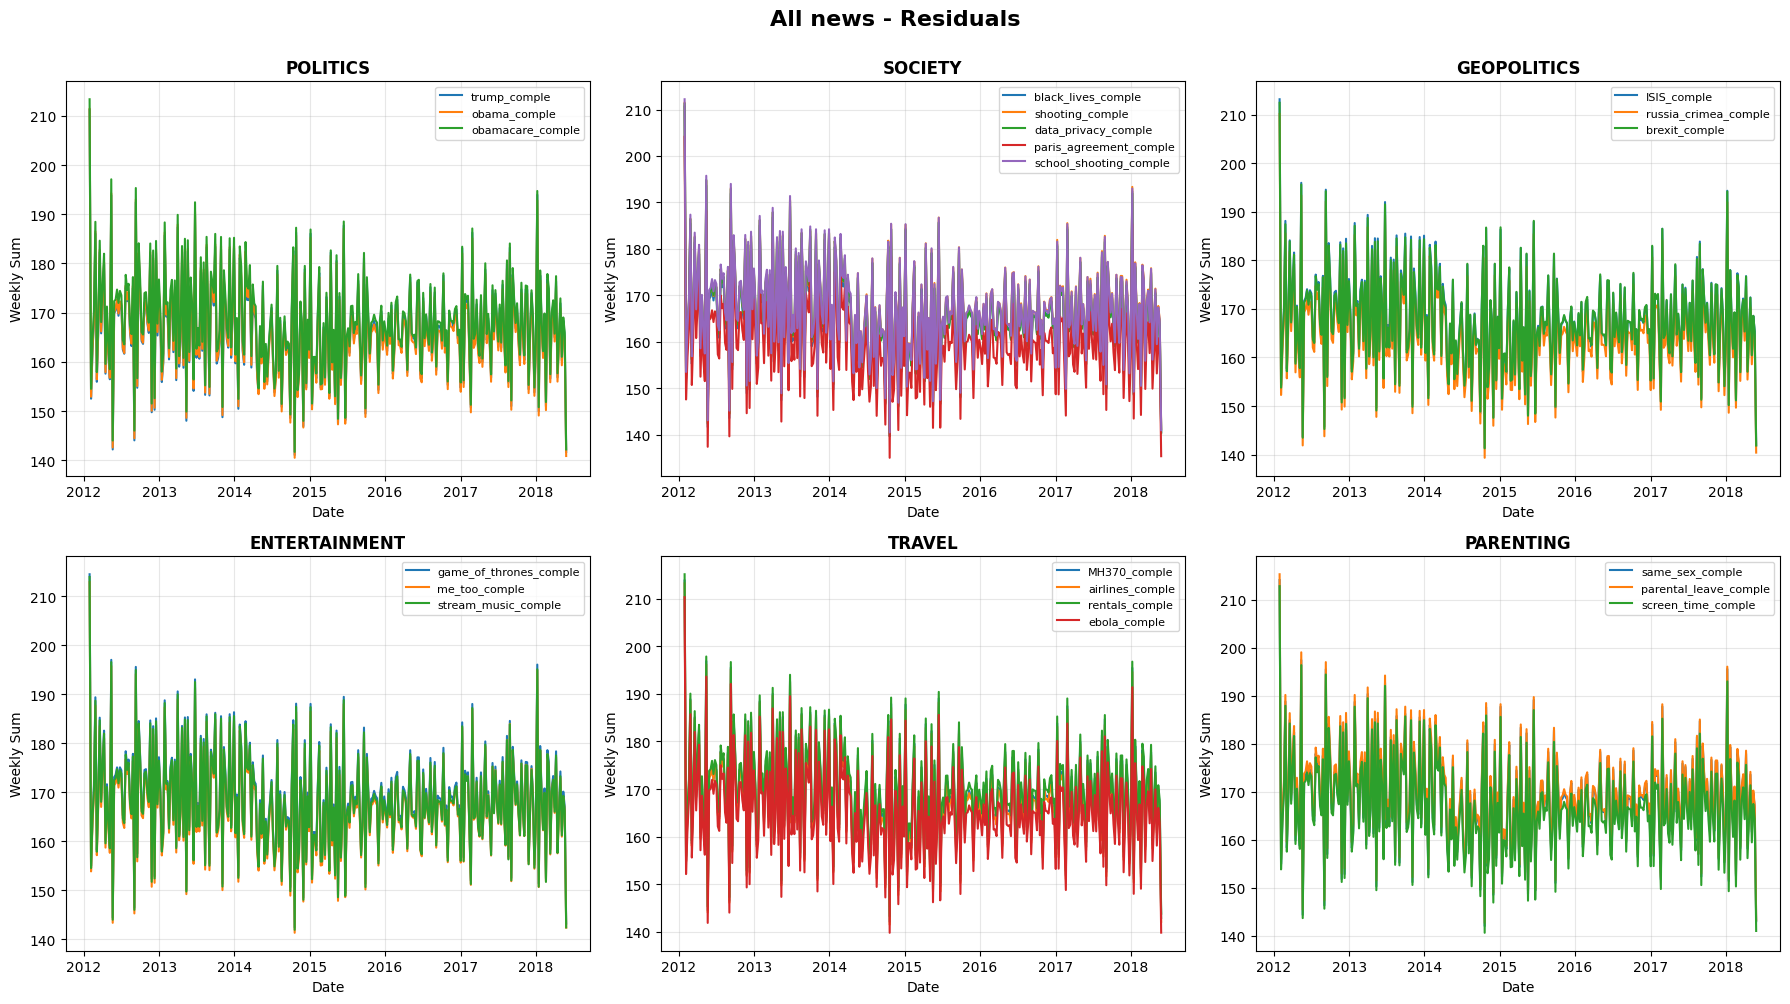

In [31]:
""" Visualization of cosine time series for pure narratives """


# Create subplots: one per chapter (6 chapters)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
    
for ax_idx, chapter in enumerate(chapter_names):
    chapter_residual_cols = [col for col in residuals_cols if col.startswith(chapter + ':')]
        
    if not chapter_residual_cols:
        axes[ax_idx].set_visible(False)
        continue
        
    for col in chapter_residual_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].sum()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        axes[ax_idx].plot(dates, cosine_similarities, label=narrative_name)
        
        axes[ax_idx].set_title(f'{chapter.upper()}', fontsize=12, fontweight='bold')
        axes[ax_idx].set_xlabel('Date', fontsize=10)
        axes[ax_idx].set_ylabel('Weekly Sum', fontsize=10)
        axes[ax_idx].legend(fontsize=8)
        axes[ax_idx].grid(True, alpha=0.3)
    
fig.suptitle('All news - Residuals', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


**V.2 Visualization excluding chapters from the dataset**

To monitor our results, we are excluding the news from the relevant chapter for the narratives

['ENTERTAINMENT', 'PARENTING', 'POLITICS', 'TRAVEL']


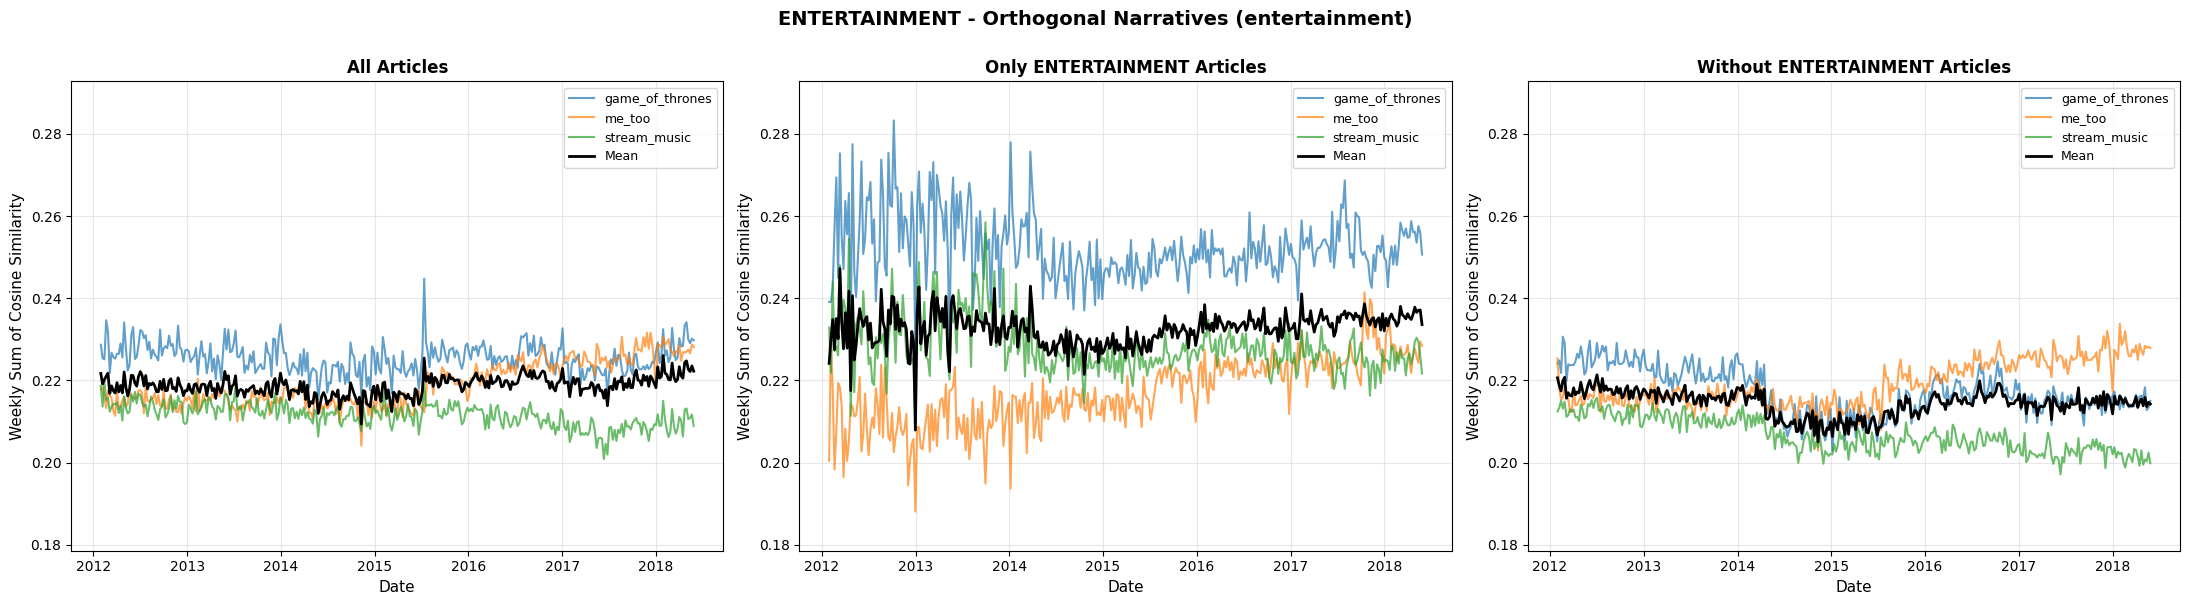

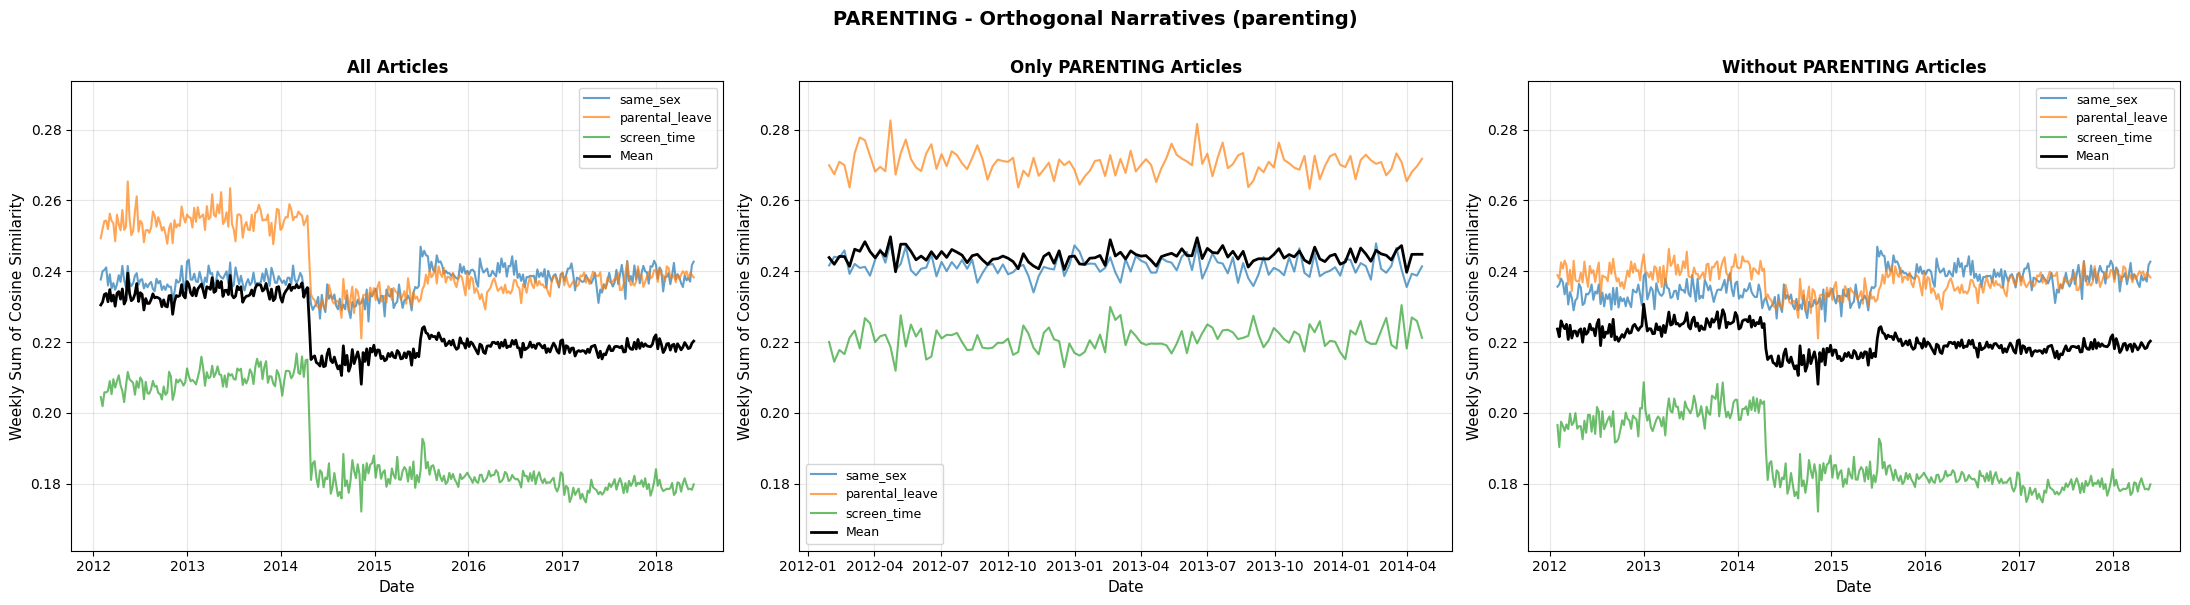

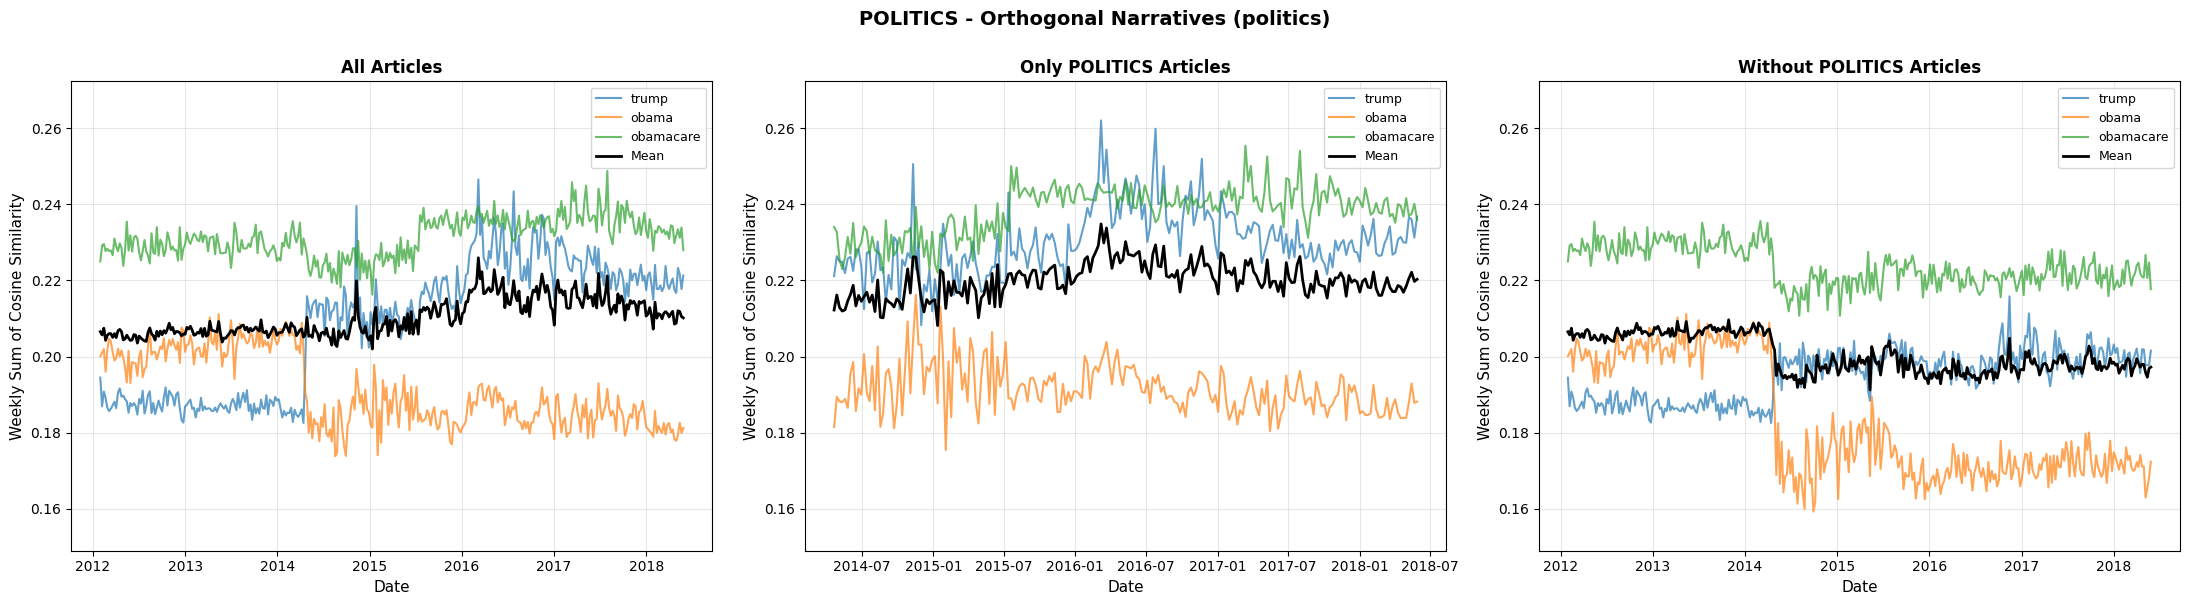

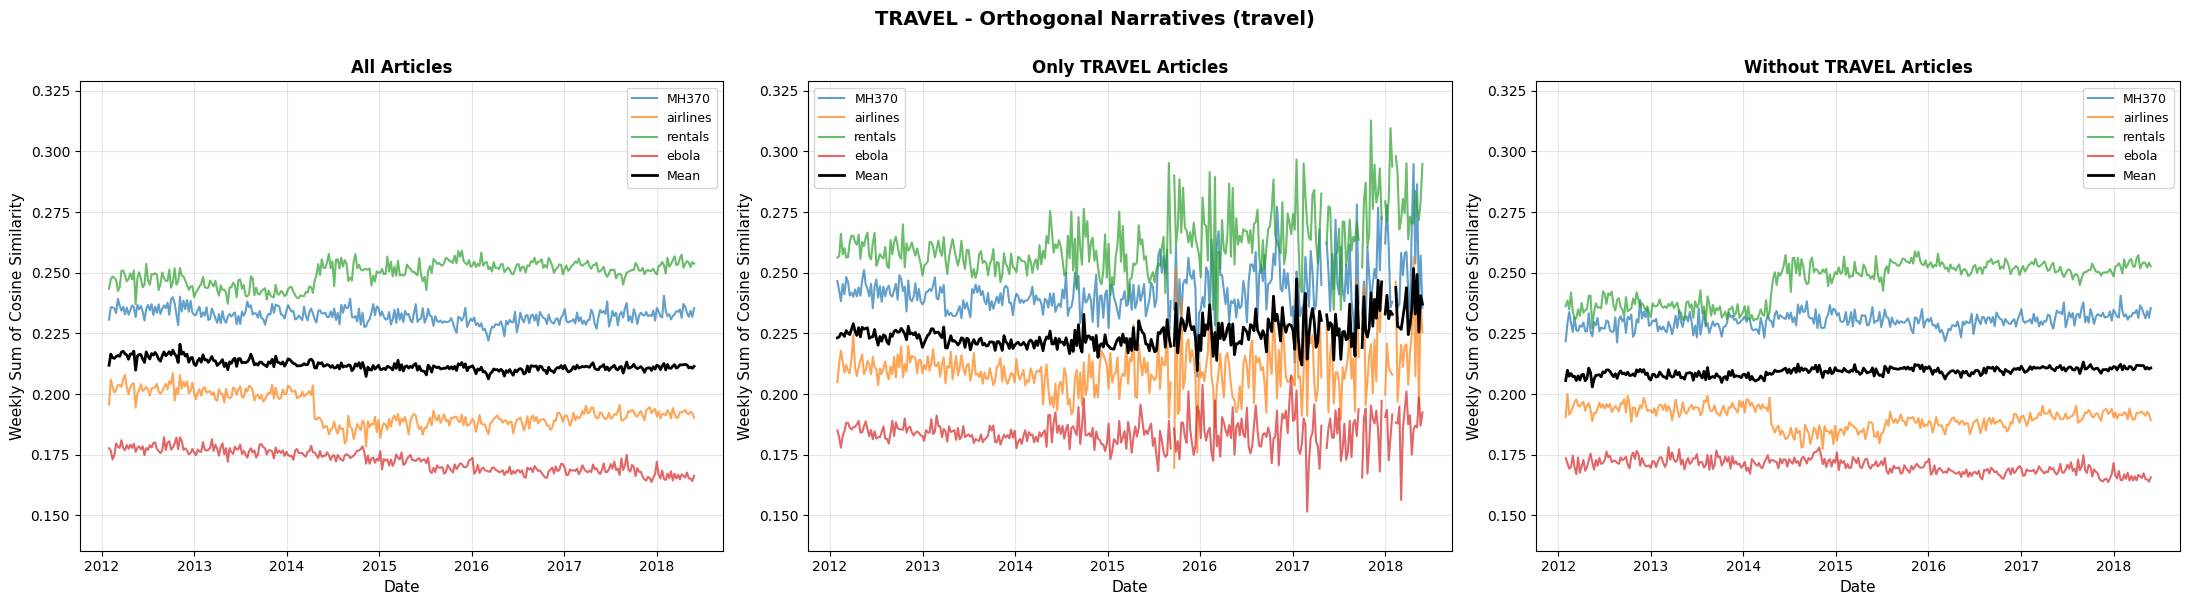

In [32]:
# Get unique news categories
news_categories = sorted(ts_df['category'].unique())
print(news_categories)

# Map news categories to their corresponding chapters
category_to_chapter = {
    'POLITICS': 'politics',
    'ENTERTAINMENT': 'entertainment',
    'TRAVEL': 'travel',
    'PARENTING': 'parenting'
}

""" Visualization of ORTHOGONAL narratives - 3 GRAPHS PER CATEGORY """

for news_cat in news_categories:
    if news_cat not in category_to_chapter:
        continue
    
    corresponding_chapter = category_to_chapter[news_cat]
    chapter_orthogonal_cols = [col for col in orthogonal_cols if col.startswith(corresponding_chapter + ':')]
    
    if not chapter_orthogonal_cols:
        continue
    
    # Filter data
    ts_df_filtered = ts_df[ts_df['category'] == news_cat]
    ts_df_without_cat = ts_df[ts_df['category'] != news_cat]
    
    # Create 3-column figure
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))
    
    # Compute global min/max for consistent scaling
    y_min, y_max = float('inf'), float('-inf')
    
    for col in chapter_orthogonal_cols:
        # All data
        sim_all = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_all.min())
        y_max = max(y_max, sim_all.max())
        
        # Only this category
        sim_cat = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_cat.min())
        y_max = max(y_max, sim_cat.max())
        
        # Without this category
        sim_without = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        y_min = min(y_min, sim_without.min())
        y_max = max(y_max, sim_without.max())
    
    padding = (y_max - y_min) * 0.1
    y_min -= padding
    y_max += padding
    
    # GRAPH 1: All data
    all_curves_1 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax1.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_1.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_1:
        mean_curve_1 = np.mean(all_curves_1, axis=0)
        ax1.plot(dates, mean_curve_1, color='black', linewidth=2, label='Mean')
    
    ax1.set_title(f'All Articles', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Date', fontsize=11)
    ax1.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax1.set_ylim(y_min, y_max)
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)
    
    # GRAPH 2: Only this category
    all_curves_2 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_filtered.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax2.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_2.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_2:
        mean_curve_2 = np.mean(all_curves_2, axis=0)
        ax2.plot(dates, mean_curve_2, color='black', linewidth=2, label='Mean')
    
    ax2.set_title(f'Only {news_cat} Articles', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Date', fontsize=11)
    ax2.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax2.set_ylim(y_min, y_max)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)
    
    # GRAPH 3: Without this category
    all_curves_3 = []
    for col in chapter_orthogonal_cols:
        cosine_similarities = ts_df_without_cat.groupby(pd.Grouper(key='date_dt', freq='W-MON'))[col].mean()
        dates = cosine_similarities.index
        narrative_name = col.split(':')[1].replace('_orth', '')
        ax3.plot(dates, cosine_similarities, label=narrative_name, alpha=0.7)
        all_curves_3.append(cosine_similarities.values)
    
    # Plot mean in black
    if all_curves_3:
        mean_curve_3 = np.mean(all_curves_3, axis=0)
        ax3.plot(dates, mean_curve_3, color='black', linewidth=2, label='Mean')
    
    ax3.set_title(f'Without {news_cat} Articles', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Date', fontsize=11)
    ax3.set_ylabel('Weekly Sum of Cosine Similarity', fontsize=11)
    ax3.set_ylim(y_min, y_max)
    ax3.legend(fontsize=9)
    ax3.grid(True, alpha=0.3)
    
    fig.suptitle(f'{news_cat.upper()} - Orthogonal Narratives ({corresponding_chapter})', fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

In [33]:
top_20 = ts_df[orthogonal_cols].stack().nlargest(30)
for (indx, narr), value in top_20.items():
    print(f"{indx}: category: {ts_df.iloc[indx]['category']}, headline: {ts_df.iloc[indx]['headline']}, narrative: {narr},  value: {value:.4f}")

38803: category: POLITICS, headline: Bernie Sanders To Receive Secret Service Protection, narrative: politics:trump_orth,  value: 0.4079
54450: category: POLITICS, headline: Remembering Betty Ong, narrative: travel:MH370_orth,  value: 0.3942
30419: category: POLITICS, headline: Democrats Endorse Donald Trump In 2016 Presidential Race, narrative: politics:trump_orth,  value: 0.3932
42309: category: POLITICS, headline: Libertarian Gary Johnson: Jeb Bush And Anti-Trump Republicans Will Vote For Me, narrative: politics:trump_orth,  value: 0.3926
41119: category: POLITICS, headline: Donald Trump Wins Delaware Republican Presidential Primary, narrative: politics:trump_orth,  value: 0.3917
34234: category: POLITICS, headline: Obamacare Safety Net Catching People Who Lose Health Insurance, narrative: politics:obamacare_orth,  value: 0.3912
30022: category: POLITICS, headline: Alabama Supreme Court Blocks Same-Sex Marriage, narrative: parenting:same_sex_orth,  value: 0.3874
30062: category: POL

In [34]:
top_20 = ts_df[narrative_cols].stack().nlargest(30)
for (indx, narr), value in top_20.items():
    print(f"{indx}: category: {ts_df.iloc[indx]['category']}, headline: {ts_df.iloc[indx]['headline']}, narrative: {narr},  value: {value:.4f}")

32932: category: POLITICS, headline: Marriage Equality and Science, narrative: parenting:same_sex,  value: 0.9709
33021: category: POLITICS, headline: The Warren vs Roberts Courts: Separate and Unequal Views on Marriage Equality, narrative: parenting:same_sex,  value: 0.9707
10195: category: PARENTING, headline: Can Too Much Screen Time Harm Your Child?, narrative: parenting:screen_time,  value: 0.9693
10221: category: PARENTING, headline: Can Too Much Screen Time Harm Your Child?, narrative: parenting:screen_time,  value: 0.9693
10234: category: PARENTING, headline: Can Too Much Screen Time Harm Your Child?, narrative: parenting:screen_time,  value: 0.9693
10255: category: PARENTING, headline: Can Too Much Screen Time Harm Your Child?, narrative: parenting:screen_time,  value: 0.9693
27206: category: POLITICS, headline: Same-Sex Marriage and Physician-Assisted Dying: The Connection, narrative: parenting:same_sex,  value: 0.9678
22643: category: POLITICS, headline: Elections in Ukraine